# ECG Signal Denoising and Quality Enhancement — Version 2

### Software-only ECG DSP project

This notebook loads a real MIT-BIH ECG, adds controlled synthetic noise, applies FIR filtering, compares filter configurations, evaluates SNR/RMSE/correlation, performs FFT analysis, and checks R-peak/QRS preservation.

**Run all cells from top to bottom.**


In [17]:
!pip -q install numpy scipy pandas matplotlib wfdb

## 1. Imports and Configuration


In [18]:
"""
ECG Signal Denoising and Quality Enhancement Using Digital FIR Filtering
Version 2 — Software-only project

Real ECG source:
    MIT-BIH Arrhythmia Database, record 100, accessed through WFDB.

Experiments:
    - Mixed noise
    - Individual noise types
    - FIR window/order comparison
    - Input SNR sweep
    - FFT analysis
    - R-peak/QRS preservation

This is an academic signal-processing project, not a clinical diagnostic tool.
"""

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import rfft, rfftfreq
import wfdb

warnings.filterwarnings("ignore")

# ============================================================
# CONFIGURATION
# ============================================================

RECORD_NAME = "100"
CHANNEL = 0
DURATION_SEC = 10

# MIT-BIH record 100 is sampled at 360 Hz.
# We still read the actual sampling rate from the record.
DEFAULT_FS = 360

MIXED_INPUT_SNR_DB = 10

FILTER_ORDERS = [20, 40, 60, 80, 100]
WINDOWS = ["hamming", "hann", "blackman"]

# Software band-pass used for ECG denoising.
# The project is evaluating waveform preservation, not clinical diagnosis.
LOW_CUTOFF_HZ = 0.5
HIGH_CUTOFF_HZ = 40.0

RANDOM_SEED = 42

BASE_DIR = Path("/content")
PLOT_DIR = BASE_DIR / "plots"
RESULT_DIR = BASE_DIR / "results"

PLOT_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

np.random.seed(RANDOM_SEED)




## 2. Utility Functions


In [19]:
# ============================================================
# UTILITY
# ============================================================

def print_header(title):
    print("\n" + "=" * 72)
    print(title)
    print("=" * 72)


def normalize_signal(x):
    x = np.asarray(x, dtype=float)
    x = x - np.mean(x)
    scale = np.max(np.abs(x))
    return x / scale if scale > 0 else x




## 3. ECG Loading


In [20]:
# ============================================================
# 1. LOAD REAL MIT-BIH ECG
# ============================================================

def load_real_ecg(record_name=RECORD_NAME, channel=CHANNEL,
                  duration_sec=DURATION_SEC):
    """
    Load a real ECG recording from MIT-BIH through WFDB.

    WFDB downloads the record automatically when pn_dir="mitdb".
    """
    print_header("1. LOADING REAL MIT-BIH ECG")

    print(f"Record      : {record_name}")
    print("Database    : MIT-BIH Arrhythmia Database")
    print("Channel     :", channel)

    record = wfdb.rdrecord(record_name, pn_dir="mitdb")

    fs = float(record.fs)

    if channel >= record.p_signal.shape[1]:
        raise ValueError(
            f"Channel {channel} unavailable. "
            f"Record has {record.p_signal.shape[1]} channels."
        )

    ecg = record.p_signal[:, channel].astype(float)

    n_samples = min(
        len(ecg),
        int(duration_sec * fs)
    )

    ecg = ecg[:n_samples]
    t = np.arange(n_samples) / fs

    # Remove DC and normalize only for controlled software experiments.
    ecg = normalize_signal(ecg)

    print(f"Sampling rate: {fs:g} Hz")
    print(f"Samples      : {len(ecg)}")
    print(f"Duration     : {len(ecg) / fs:.2f} s")

    return t, ecg, fs




## 4. Noise Generation


In [21]:
# ============================================================
# 2. NOISE GENERATION
# ============================================================

def add_baseline_wander(ecg, fs, amplitude=0.15):
    t = np.arange(len(ecg)) / fs

    baseline = (
        amplitude * np.sin(2 * np.pi * 0.25 * t)
        + 0.04 * np.sin(2 * np.pi * 0.35 * t)
    )

    return ecg + baseline


def add_powerline_noise(ecg, fs, amplitude=0.08, frequency=50):
    t = np.arange(len(ecg)) / fs

    powerline = amplitude * np.sin(
        2 * np.pi * frequency * t
    )

    return ecg + powerline


def add_emg_noise(ecg, fs, amplitude=0.12):
    """
    Create broadband/high-frequency EMG-like noise by filtering
    Gaussian noise into approximately the 40–100 Hz range.
    """
    raw = np.random.randn(len(ecg))

    high = min(100.0, fs / 2 - 2.0)
    low = min(40.0, high - 2.0)

    b, a = signal.butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs
    )

    emg = signal.filtfilt(b, a, raw)

    rms = np.sqrt(np.mean(emg ** 2))
    if rms > 0:
        emg = emg / rms

    return ecg + amplitude * emg


def add_awgn(ecg, snr_db):
    """
    Add Gaussian noise to achieve approximately the requested SNR.
    """
    signal_power = np.mean(ecg ** 2)
    noise_power = signal_power / (10 ** (snr_db / 10))

    noise = np.random.randn(len(ecg))
    noise = noise / np.sqrt(np.mean(noise ** 2))

    return ecg + np.sqrt(noise_power) * noise


def create_mixed_noise(ecg, fs, input_snr_db=MIXED_INPUT_SNR_DB):
    """
    Add deterministic components first, then scale AWGN to the
    requested SNR relative to the original ECG.
    """
    noisy = ecg.copy()

    noisy = add_baseline_wander(
        noisy, fs, amplitude=0.15
    )

    noisy = add_powerline_noise(
        noisy, fs, amplitude=0.08, frequency=50
    )

    noisy = add_emg_noise(
        noisy, fs, amplitude=0.08
    )

    # Add AWGN with requested nominal SNR relative to original ECG.
    noisy = add_awgn(
        noisy, input_snr_db
    )

    return noisy




## 5. Metrics


In [22]:
# ============================================================
# 3. METRICS
# ============================================================

def mse(clean, test):
    return float(np.mean((clean - test) ** 2))


def rmse(clean, test):
    return float(np.sqrt(mse(clean, test)))


def correlation(clean, test):
    value = np.corrcoef(clean, test)[0, 1]
    return float(value)


def snr(clean, test):
    """
    SNR relative to a clean/reference signal:
        10 log10(P_signal / P_error)
    """
    error = clean - test

    signal_power = np.mean(clean ** 2)
    error_power = np.mean(error ** 2)

    if error_power <= 0:
        return np.inf

    return float(
        10 * np.log10(signal_power / error_power)
    )




## 6. FIR Filter


In [23]:
# ============================================================
# 4. FIR FILTER  (improved: high-pass for baseline + FIR low-pass)
# ============================================================

def design_fir(fs, order, window):
    """
    Linear-phase FIR LOW-PASS filter (removes EMG, 50 Hz, hiss).
    The baseline wander is removed separately in apply_fir().
    """
    nyquist = fs / 2

    if HIGH_CUTOFF_HZ >= nyquist:
        raise ValueError("High cutoff must be below Nyquist frequency.")

    coefficients = signal.firwin(
        numtaps=order + 1,
        cutoff=HIGH_CUTOFF_HZ,
        window=window,
        fs=fs
    )

    return coefficients


def apply_fir(ecg, coefficients, fs=360):
    """
    Zero-phase two-stage filtering:
      1) Butterworth high-pass at LOW_CUTOFF_HZ (baseline wander)
      2) FIR low-pass with the given coefficients
    """
    sos = signal.butter(
        2, LOW_CUTOFF_HZ, btype="high", fs=fs, output="sos"
    )

    padlen = min(3 * int(fs), len(ecg) - 1)
    x = signal.sosfiltfilt(sos, ecg, padlen=padlen)

    return signal.filtfilt(coefficients, [1.0], x)



## 7. FFT


In [24]:
# ============================================================
# 5. FFT
# ============================================================

def fft_data(x, fs):
    n = len(x)

    frequencies = rfftfreq(
        n,
        d=1 / fs
    )

    magnitude = np.abs(
        rfft(x)
    ) / n

    return frequencies, magnitude




## 8. R-Peak / QRS Detection


In [25]:
# ============================================================
# 6. R-PEAK DETECTION
# ============================================================

def detect_r_peaks(ecg, fs):
    """
    Simple software R-peak detector based on:
        - differentiation
        - squaring
        - moving integration
        - distance/height based peak detection

    It is intentionally kept transparent for a student project.
    It is not a clinical-grade ECG detector.
    """

    x = np.asarray(ecg, dtype=float)

    # Remove slow baseline for detection.
    b, a = signal.butter(
        2,
        5.0,
        btype="highpass",
        fs=fs
    )

    x_hp = signal.filtfilt(
        b, a, x
    )

    # Derivative
    derivative = np.diff(
        x_hp,
        prepend=x_hp[0]
    )

    # Squaring
    squared = derivative ** 2

    # Moving-window integration
    window_samples = max(
        1,
        int(0.12 * fs)
    )

    kernel = np.ones(
        window_samples
    ) / window_samples

    integrated = np.convolve(
        squared,
        kernel,
        mode="same"
    )

    # Dynamic threshold
    threshold = (
        np.mean(integrated)
        + 0.5 * np.std(integrated)
    )

    min_distance = int(
        0.25 * fs
    )

    peaks, _ = signal.find_peaks(
        integrated,
        height=threshold,
        distance=min_distance
    )

    # The integrated peak is near, but not always exactly at,
    # the R peak. Search around it for the maximum absolute ECG.
    search_radius = int(0.08 * fs)

    refined = []

    for p in peaks:
        left = max(0, p - search_radius)
        right = min(
            len(x),
            p + search_radius + 1
        )

        local = x_hp[left:right]

        if len(local) == 0:
            continue

        local_index = np.argmax(
            np.abs(local)
        )

        refined.append(
            left + local_index
        )

    # Remove duplicates.
    refined = np.array(
        sorted(set(refined)),
        dtype=int
    )

    return refined


def match_peaks(reference_peaks, test_peaks, tolerance_samples):
    """
    Greedy one-to-one peak matching.
    Returns TP, FP, FN.
    """
    reference_peaks = np.asarray(
        reference_peaks,
        dtype=int
    )

    test_peaks = np.asarray(
        test_peaks,
        dtype=int
    )

    used = set()
    tp = 0

    for ref in reference_peaks:
        if len(test_peaks) == 0:
            continue

        distances = np.abs(
            test_peaks - ref
        )

        order = np.argsort(
            distances
        )

        matched = False

        for idx in order:
            idx = int(idx)

            if idx in used:
                continue

            if distances[idx] <= tolerance_samples:
                used.add(idx)
                tp += 1
                matched = True
                break

        if not matched:
            pass

    fp = len(test_peaks) - tp
    fn = len(reference_peaks) - tp

    return tp, fp, fn


def peak_metrics(reference_peaks, test_peaks, fs):
    tolerance = int(
        0.10 * fs
    )

    tp, fp, fn = match_peaks(
        reference_peaks,
        test_peaks,
        tolerance
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    if precision + recall > 0:
        f1 = (
            2 * precision * recall
            / (precision + recall)
        )
    else:
        f1 = 0.0

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }




## 9. Plotting Functions


In [26]:
# ============================================================
# 7. PLOTTING
# ============================================================

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        PLOT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


def plot_clean_ecg(t, clean):
    plt.figure(figsize=(12, 4))
    plt.plot(t, clean, linewidth=1)
    plt.xlabel("Time (s)")
    plt.ylabel("Normalized amplitude")
    plt.title("Real MIT-BIH ECG — Clean Reference")
    plt.grid(True)
    save_plot("01_clean_ecg.png")


def plot_noisy_ecg(t, noisy):
    plt.figure(figsize=(12, 4))
    plt.plot(t, noisy, linewidth=1)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title("ECG with Mixed Synthetic Noise")
    plt.grid(True)
    save_plot("02_mixed_noisy_ecg.png")


def plot_filtered_ecg(t, filtered):
    plt.figure(figsize=(12, 4))
    plt.plot(t, filtered, linewidth=1)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title("FIR-Filtered ECG")
    plt.grid(True)
    save_plot("03_filtered_ecg.png")


def plot_three_signals(t, clean, noisy, filtered):
    plt.figure(figsize=(12, 5))

    plt.plot(
        t,
        clean,
        label="Clean reference",
        linewidth=1.2
    )

    plt.plot(
        t,
        noisy,
        label="Noisy ECG",
        alpha=0.65,
        linewidth=1
    )

    plt.plot(
        t,
        filtered,
        label="Filtered ECG",
        linewidth=1.2
    )

    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title("Clean vs Noisy vs Filtered ECG")

    plt.legend()
    plt.grid(True)

    save_plot("04_clean_noisy_filtered.png")


def plot_fft_comparison(noisy, filtered, fs):
    f1, m1 = fft_data(noisy, fs)
    f2, m2 = fft_data(filtered, fs)

    plt.figure(figsize=(12, 5))

    plt.plot(
        f1,
        m1,
        label="Before filtering"
    )

    plt.plot(
        f2,
        m2,
        label="After filtering"
    )

    plt.xlim(0, min(120, fs / 2))

    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.title("Frequency Spectrum Before and After FIR Filtering")

    plt.legend()
    plt.grid(True)

    save_plot("05_fft_before_after.png")


def plot_fft_separate(noisy, filtered, fs):
    f1, m1 = fft_data(noisy, fs)

    plt.figure(figsize=(12, 4))
    plt.plot(f1, m1)
    plt.xlim(0, min(120, fs / 2))
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.title("FFT of Noisy ECG")
    plt.grid(True)
    save_plot("05_fft_before.png")

    f2, m2 = fft_data(filtered, fs)

    plt.figure(figsize=(12, 4))
    plt.plot(f2, m2)
    plt.xlim(0, min(120, fs / 2))
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.title("FFT of Filtered ECG")
    plt.grid(True)
    save_plot("06_fft_after.png")


def plot_fir_response(coefficients, fs, order, window):
    f, h = signal.freqz(
        coefficients,
        worN=4096,
        fs=fs
    )

    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(h), 1e-10)
    )

    plt.figure(figsize=(12, 5))
    plt.plot(f, magnitude_db)

    plt.xlim(0, min(120, fs / 2))
    plt.ylim(-100, 10)

    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")

    plt.title(
        f"FIR Frequency Response — Order {order}, {window}"
    )

    plt.grid(True)

    save_plot("07_fir_response.png")


def plot_filter_comparison(df):
    for metric, ylabel, filename, title in [
        (
            "SNR_Improvement_dB",
            "SNR Improvement (dB)",
            "08_snr_vs_order.png",
            "SNR Improvement vs FIR Order"
        ),
        (
            "RMSE",
            "RMSE",
            "09_rmse_vs_order.png",
            "RMSE vs FIR Order"
        ),
        (
            "Correlation",
            "Correlation",
            "10_correlation_vs_order.png",
            "Correlation vs FIR Order"
        )
    ]:

        plt.figure(figsize=(10, 6))

        for window in WINDOWS:

            subset = df[
                df["Window"] == window
            ]

            plt.plot(
                subset["Order"],
                subset[metric],
                marker="o",
                label=window
            )

        plt.xlabel("FIR Filter Order")
        plt.ylabel(ylabel)
        plt.title(title)

        plt.legend()
        plt.grid(True)

        save_plot(filename)


def plot_snr_sweep(df):
    plt.figure(figsize=(10, 6))

    plt.plot(
        df["Measured_Input_SNR_dB"],
        df["Output_SNR_dB"],
        marker="o",
        label="Filtered output"
    )

    plt.plot(
        df["Measured_Input_SNR_dB"],
        df["Measured_Input_SNR_dB"],
        linestyle="--",
        label="Input reference"
    )

    plt.xlabel("Input SNR (dB)")
    plt.ylabel("SNR (dB)")
    plt.title("Input SNR vs Output SNR")

    plt.legend()
    plt.grid(True)

    save_plot("11_input_vs_output_snr.png")


def plot_noise_comparison(df):
    plt.figure(figsize=(10, 6))

    plt.bar(
        df["Noise_Type"],
        df["SNR_Improvement_dB"]
    )

    plt.ylabel("SNR Improvement (dB)")
    plt.xlabel("Noise Type")
    plt.title("FIR Performance Under Different Noise Types")

    plt.xticks(rotation=20)
    plt.grid(axis="y")

    save_plot("12_noise_type_snr.png")


def plot_qrs_comparison(df):
    plt.figure(figsize=(10, 6))

    x = np.arange(len(df))

    plt.bar(
        x - 0.18,
        df["Precision"],
        width=0.18,
        label="Precision"
    )

    plt.bar(
        x,
        df["Recall"],
        width=0.18,
        label="Recall"
    )

    plt.bar(
        x + 0.18,
        df["F1"],
        width=0.18,
        label="F1"
    )

    plt.xticks(
        x,
        df["Signal"]
    )

    plt.ylim(0, 1.05)

    plt.ylabel("Score")
    plt.xlabel("Signal")
    plt.title("R-Peak / QRS Preservation")

    plt.legend()
    plt.grid(axis="y")

    save_plot("13_qrs_preservation.png")




## 10. Filter Comparison


In [27]:
# ============================================================
# 8. FILTER COMPARISON EXPERIMENT
# ============================================================

def filter_comparison(clean, noisy, fs):
    print_header("FILTER ORDER + WINDOW COMPARISON")

    input_snr = snr(clean, noisy)

    rows = []

    for window in WINDOWS:

        for order in FILTER_ORDERS:

            coeff = design_fir(
                fs,
                order,
                window
            )

            filtered = apply_fir(
                noisy,
                coeff
            )

            output_snr = snr(
                clean,
                filtered
            )

            rows.append({
                "Window": window,
                "Order": order,
                "Input_SNR_dB": input_snr,
                "Output_SNR_dB": output_snr,
                "SNR_Improvement_dB":
                    output_snr - input_snr,
                "MSE":
                    mse(clean, filtered),
                "RMSE":
                    rmse(clean, filtered),
                "Correlation":
                    correlation(clean, filtered)
            })

    df = pd.DataFrame(rows)

    df.to_csv(
        RESULT_DIR / "filter_comparison.csv",
        index=False
    )

    print(df.to_string(index=False))

    return df




## 11. Noise-Type Experiment


In [28]:
# ============================================================
# 9. NOISE-TYPE EXPERIMENT
# ============================================================

def noise_type_experiment(clean, fs, coeff):
    print_header("INDIVIDUAL NOISE EXPERIMENT")

    experiments = {
        "Baseline Wander":
            lambda: add_baseline_wander(
                clean, fs, amplitude=0.15
            ),

        "50 Hz Powerline":
            lambda: add_powerline_noise(
                clean, fs,
                amplitude=0.08,
                frequency=50
            ),

        "EMG Noise":
            lambda: add_emg_noise(
                clean, fs,
                amplitude=0.08
            ),

        "AWGN (10 dB)":
            lambda: add_awgn(
                clean, 10
            )
    }

    rows = []

    for name, generator in experiments.items():

        noisy = generator()

        filtered = apply_fir(
            noisy,
            coeff
        )

        input_snr = snr(
            clean,
            noisy
        )

        output_snr = snr(
            clean,
            filtered
        )

        rows.append({
            "Noise_Type": name,
            "Input_SNR_dB": input_snr,
            "Output_SNR_dB": output_snr,
            "SNR_Improvement_dB":
                output_snr - input_snr,
            "RMSE":
                rmse(clean, filtered),
            "Correlation":
                correlation(clean, filtered)
        })

    df = pd.DataFrame(rows)

    df.to_csv(
        RESULT_DIR / "noise_comparison.csv",
        index=False
    )

    print(df.to_string(index=False))

    return df




## 12. Input-SNR Sweep


In [29]:
# ============================================================
# 10. INPUT-SNR SWEEP
# ============================================================

def snr_sweep(clean, fs, coeff):
    print_header("INPUT SNR SWEEP")

    target_snrs = [
        0, 5, 10, 15, 20
    ]

    rows = []

    for target in target_snrs:

        noisy = add_awgn(
            clean,
            target
        )

        filtered = apply_fir(
            noisy,
            coeff
        )

        measured_input = snr(
            clean,
            noisy
        )

        output = snr(
            clean,
            filtered
        )

        rows.append({
            "Target_Input_SNR_dB": target,
            "Measured_Input_SNR_dB": measured_input,
            "Output_SNR_dB": output,
            "SNR_Improvement_dB":
                output - measured_input,
            "RMSE":
                rmse(clean, filtered),
            "Correlation":
                correlation(clean, filtered)
        })

    df = pd.DataFrame(rows)

    df.to_csv(
        RESULT_DIR / "snr_sweep.csv",
        index=False
    )

    print(df.to_string(index=False))

    return df




## 13. QRS/R-Peak Preservation


In [30]:
# ============================================================
# 11. QRS/R-PEAK PRESERVATION EXPERIMENT
# ============================================================

def qrs_preservation_experiment(
    clean,
    noisy,
    filtered,
    fs
):
    print_header("R-PEAK / QRS PRESERVATION")

    clean_peaks = detect_r_peaks(
        clean,
        fs
    )

    noisy_peaks = detect_r_peaks(
        noisy,
        fs
    )

    filtered_peaks = detect_r_peaks(
        filtered,
        fs
    )

    clean_vs_noisy = peak_metrics(
        clean_peaks,
        noisy_peaks,
        fs
    )

    clean_vs_filtered = peak_metrics(
        clean_peaks,
        filtered_peaks,
        fs
    )

    rows = [
        {
            "Signal": "Noisy",
            **clean_vs_noisy
        },
        {
            "Signal": "Filtered",
            **clean_vs_filtered
        }
    ]

    df = pd.DataFrame(rows)

    df.to_csv(
        RESULT_DIR / "qrs_comparison.csv",
        index=False
    )

    print(
        f"Reference R-peaks detected : "
        f"{len(clean_peaks)}"
    )

    print(
        f"Noisy R-peaks detected     : "
        f"{len(noisy_peaks)}"
    )

    print(
        f"Filtered R-peaks detected  : "
        f"{len(filtered_peaks)}"
    )

    print("\n" + df.to_string(index=False))

    return df, clean_peaks, noisy_peaks, filtered_peaks




## 14. Final Summary Functions


In [31]:
# ============================================================
# 12. BEST FILTER SELECTION
# ============================================================

def select_best_configuration(df):
    """
    Select the configuration with maximum SNR improvement.
    This is an experimental selection criterion, not a clinical
    'best filter' claim.
    """
    index = df[
        "SNR_Improvement_dB"
    ].idxmax()

    row = df.loc[index]

    return row


# ============================================================
# 13. SAVE FINAL SUMMARY
# ============================================================

def save_summary(
    best,
    input_snr,
    output_snr,
    snr_improvement,
    final_rmse,
    final_corr,
    qrs_df
):
    summary = f"""
ECG SIGNAL DENOISING PROJECT — VERSION 2
=========================================

Data:
    Database: MIT-BIH Arrhythmia Database
    Record: {RECORD_NAME}
    Duration: {DURATION_SEC} seconds

Final mixed-noise experiment:
    Input SNR       : {input_snr:.4f} dB
    Output SNR      : {output_snr:.4f} dB
    SNR Improvement : {snr_improvement:.4f} dB
    RMSE            : {final_rmse:.8f}
    Correlation     : {final_corr:.6f}

Experimental filter configuration with maximum
SNR improvement in the comparison table:
    Window          : {best["Window"]}
    Order           : {int(best["Order"])}
    SNR Improvement : {best["SNR_Improvement_dB"]:.4f} dB
    RMSE            : {best["RMSE"]:.8f}
    Correlation     : {best["Correlation"]:.6f}

QRS/R-peak preservation:
{qrs_df.to_string(index=False)}

Interpretation:
The project evaluates software-based ECG signal-quality
improvement under controlled synthetic noise. Results are
quantitative signal-processing measurements and should not
be interpreted as clinical diagnosis or clinical validation.
"""

    with open(
        RESULT_DIR / "best_configuration.txt",
        "w",
        encoding="utf-8"
    ) as f:
        f.write(summary)

    print(summary)




In [32]:
# ============================================================
# 15. 1D CNN POST-PROCESSING  (FIR  ->  CNN  ->  closer to clean ECG)
# ============================================================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

CNN_SEED         = 42
CNN_TRAIN_CHUNKS = 40      # 40 x 10 s = ~6.7 min of record 100 for training
CNN_VAL_CHUNKS   = 4       # 4  x 10 s held out for validation
CNN_NOISE_COPIES = 6       # noisy versions generated per 10-s chunk
CNN_WINDOW       = 720     # 2 s training windows
CNN_STRIDE       = 360
CNN_EPOCHS       = 40
CNN_BATCH        = 32


def load_long_ecg(n_seconds):
    """Load the first n_seconds of record 100 (not normalised yet)."""
    rec = wfdb.rdrecord(RECORD_NAME, pn_dir="mitdb",
                        sampto=int(n_seconds * DEFAULT_FS))
    return rec.p_signal[:, CHANNEL].astype(float), float(rec.fs)


def random_noisy_version(clean, fs, rng):
    """Same four noise types as the main experiment, with random strengths."""
    x = add_baseline_wander(clean, fs, amplitude=rng.uniform(0.05, 0.25))
    x = add_powerline_noise(x, fs, amplitude=rng.uniform(0.03, 0.12))
    x = add_emg_noise(x, fs, amplitude=rng.uniform(0.04, 0.12))
    x = add_awgn(x, rng.uniform(5, 15))
    return x


def make_windows(clean_chunks, fs, fir_fn, copies, rng):
    """For each clean chunk: add noise -> FIR filter -> cut into windows.
    X = FIR output (CNN input), Y = clean ECG (CNN target)."""
    X, Y = [], []
    for clean in clean_chunks:
        for _ in range(copies):
            noisy = random_noisy_version(clean, fs, rng)
            fir_out = fir_fn(noisy)
            for s in range(0, len(clean) - CNN_WINDOW + 1, CNN_STRIDE):
                X.append(fir_out[s:s + CNN_WINDOW])
                Y.append(clean[s:s + CNN_WINDOW])
    X = np.asarray(X, dtype="float32")[..., None]
    Y = np.asarray(Y, dtype="float32")[..., None]
    return X, Y


def build_cnn():
    """Fully-convolutional 1D CNN. It predicts a CORRECTION that is added
    to its input (residual learning), so it can only refine the FIR output."""
    inp = layers.Input(shape=(None, 1))
    x = inp
    for filters, dil in [(32, 1), (32, 2), (64, 4), (64, 8), (32, 4), (32, 2)]:
        x = layers.Conv1D(filters, 9, padding="same",
                          dilation_rate=dil, activation="relu")(x)
    correction = layers.Conv1D(1, 9, padding="same")(x)
    out = layers.Add()([inp, correction])
    return keras.Model(inp, out, name="ecg_cnn_refiner")


def train_cnn(fs, fir_fn):
    """Train on record 100 EXCLUDING the first 10 s (that is the test segment)."""
    print_header("15a. TRAINING 1D CNN")
    state = np.random.get_state()           # keep the rest of the notebook reproducible
    np.random.seed(CNN_SEED)
    keras.utils.set_random_seed(CNN_SEED)
    rng = np.random.default_rng(CNN_SEED)

    chunk = int(10 * fs)
    n_chunks = 1 + CNN_TRAIN_CHUNKS + CNN_VAL_CHUNKS
    raw, _ = load_long_ecg(n_chunks * 10)
    chunks = [normalize_signal(raw[i*chunk:(i+1)*chunk]) for i in range(n_chunks)]
    # chunks[0]  = test segment  -> NEVER used for training/validation
    train_c = chunks[1:1 + CNN_TRAIN_CHUNKS]
    val_c   = chunks[1 + CNN_TRAIN_CHUNKS:]

    Xtr, Ytr = make_windows(train_c, fs, fir_fn, CNN_NOISE_COPIES, rng)
    Xva, Yva = make_windows(val_c,   fs, fir_fn, 2, rng)
    print(f"Training windows  : {Xtr.shape[0]}  ({CNN_WINDOW} samples each)")
    print(f"Validation windows: {Xva.shape[0]}")

    model = build_cnn()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    model.summary()

    hist = model.fit(
        Xtr, Ytr, validation_data=(Xva, Yva),
        epochs=CNN_EPOCHS, batch_size=CNN_BATCH, verbose=2,
        callbacks=[keras.callbacks.EarlyStopping(
            patience=8, restore_best_weights=True)])

    np.random.set_state(state)
    return model, hist


def cnn_experiment(t, clean, noisy, fir_out, fs, fir_fn):
    """Train the CNN, apply it to the FIR output, compare FIR vs FIR+CNN."""
    model, hist = train_cnn(fs, fir_fn)

    print_header("15b. FIR ONLY vs FIR + CNN")
    cnn_out = model.predict(fir_out.reshape(1, -1, 1).astype("float32"),
                            verbose=0)[0, :, 0].astype(float)

    ref_peaks = detect_r_peaks(clean, fs)
    rows = []
    for name, sig in [("Noisy", noisy), ("FIR only", fir_out),
                      ("FIR + CNN", cnn_out)]:
        pm = peak_metrics(ref_peaks, detect_r_peaks(sig, fs), fs)
        rows.append({"Signal": name,
                     "SNR_dB": snr(clean, sig),
                     "RMSE": rmse(clean, sig),
                     "Correlation": correlation(clean, sig),
                     "TP": pm["TP"], "FP": pm["FP"], "FN": pm["FN"],
                     "Precision": pm["Precision"], "Recall": pm["Recall"],
                     "F1": pm["F1"]})
    df = pd.DataFrame(rows)
    print(df.round(4).to_string(index=False))
    df.to_csv(RESULT_DIR / "cnn_comparison.csv", index=False)

    # ---- plots
    plt.figure(figsize=(12, 4))
    m = t <= 4
    plt.plot(t[m], clean[m],   label="Clean reference", linewidth=1.6)
    plt.plot(t[m], fir_out[m], label="FIR only",        linewidth=1, alpha=.85)
    plt.plot(t[m], cnn_out[m], label="FIR + CNN",       linewidth=1, alpha=.85)
    plt.xlabel("Time (s)"); plt.ylabel("Normalized amplitude")
    plt.title("FIR only vs FIR + CNN (first 4 s)")
    plt.legend(); plt.grid(True)
    save_plot("14_fir_vs_fir_cnn.png")

    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    for a, col, ttl in zip(ax, ["SNR_dB", "RMSE", "Correlation"],
                           ["SNR (dB)  higher = better",
                            "RMSE  lower = better",
                            "Correlation  higher = better"]):
        a.bar(df["Signal"], df[col], color=["#999", "#1f77b4", "#2ca02c"])
        a.set_title(ttl); a.grid(True, axis="y")
    save_plot("15_cnn_metric_comparison.png")

    plt.figure(figsize=(7, 4))
    plt.plot(hist.history["loss"], label="Training loss")
    plt.plot(hist.history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("CNN training curve")
    plt.legend(); plt.grid(True)
    save_plot("16_cnn_training_curve.png")

    return df, cnn_out

## 15. Run the Complete Experiment



ECG SIGNAL DENOISING AND QUALITY ENHANCEMENT — VERSION 2

1. LOADING REAL MIT-BIH ECG
Record      : 100
Database    : MIT-BIH Arrhythmia Database
Channel     : 0
Sampling rate: 360 Hz
Samples      : 3600
Duration     : 10.00 s


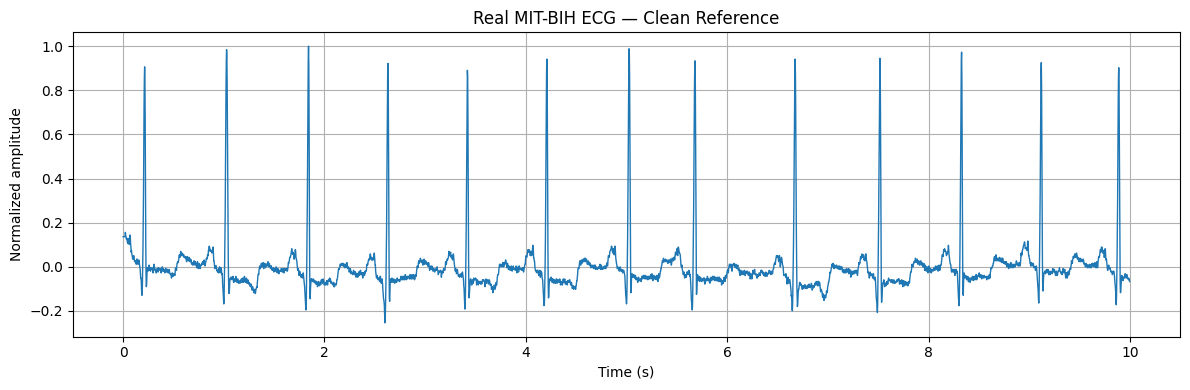


2. MIXED NOISE GENERATION


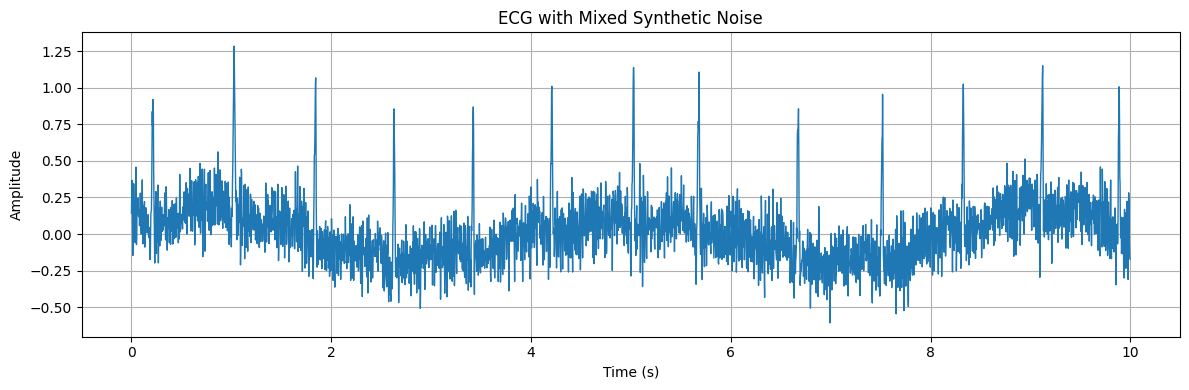

Measured input SNR: -1.694 dB

3. MAIN FIR FILTER
Filter order      : 100
Window            : hamming
Input SNR         : -1.694 dB
Output SNR        : 9.141 dB
SNR improvement   : 10.835 dB
RMSE              : 0.046431
Correlation       : 0.939462


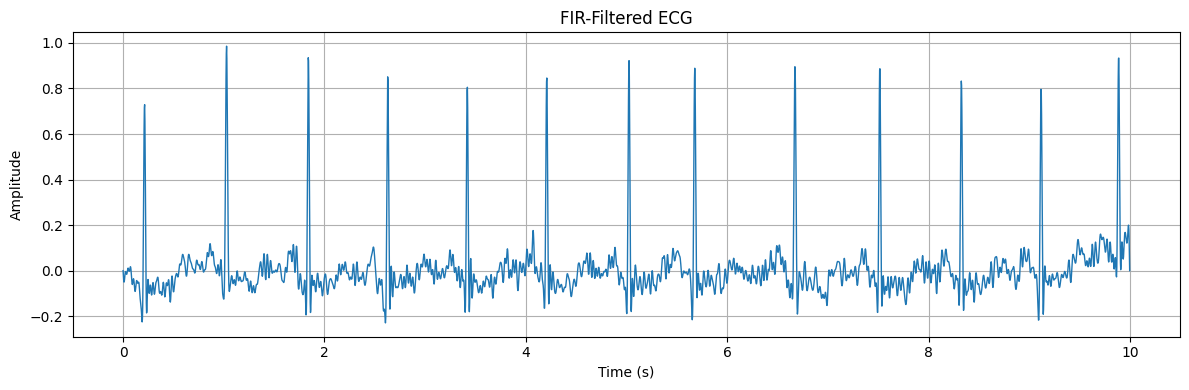

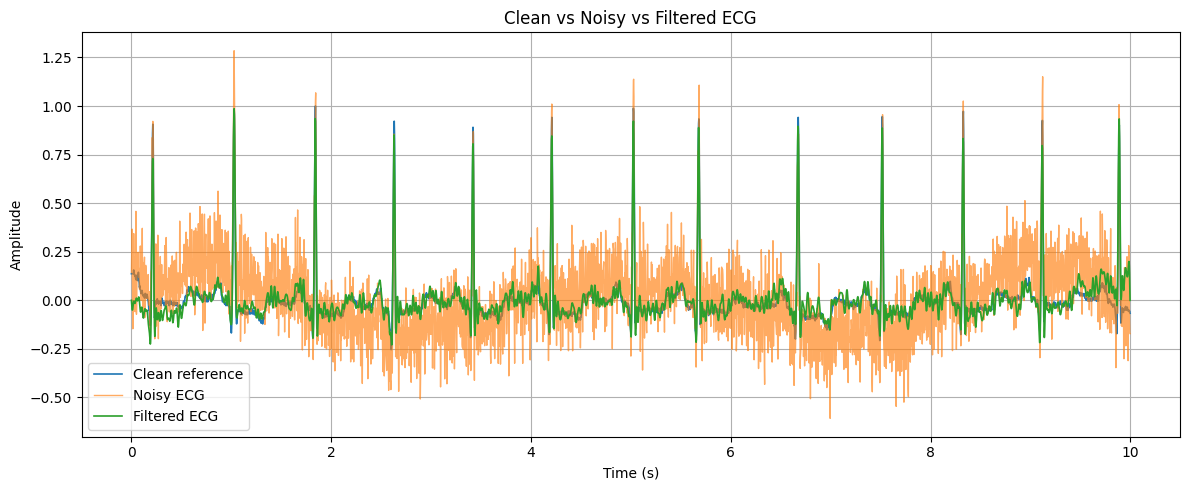

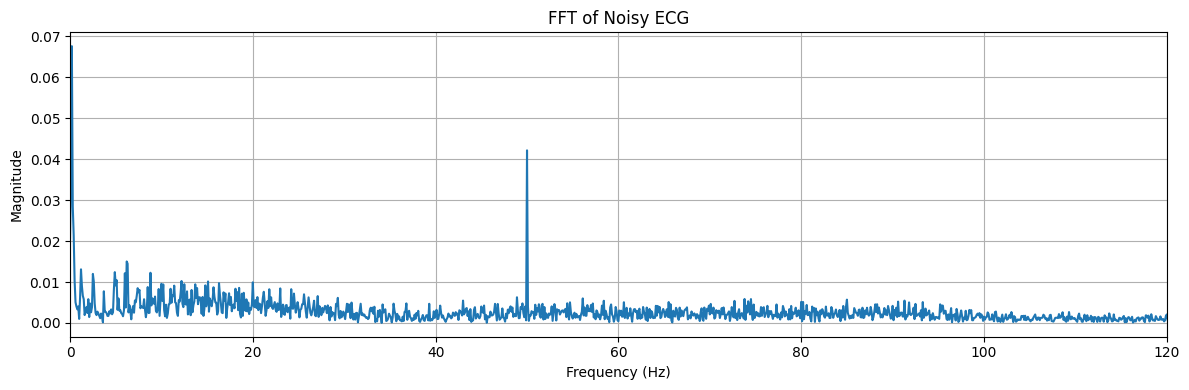

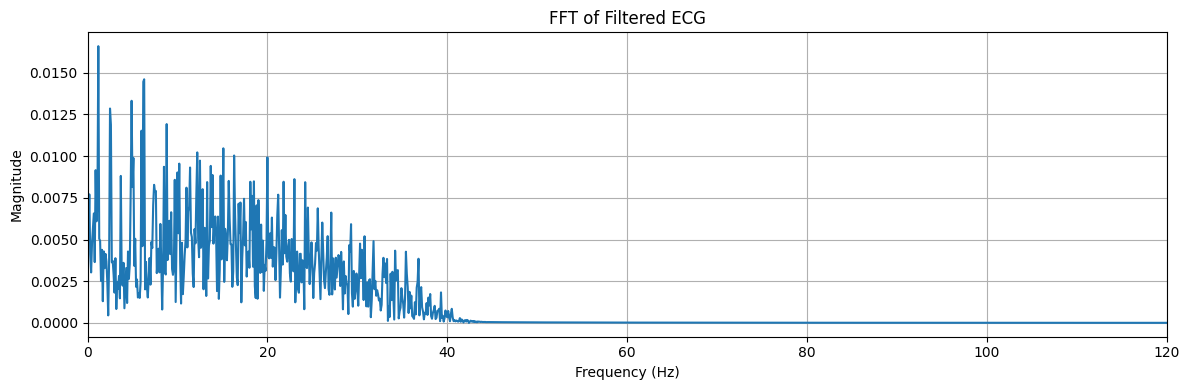

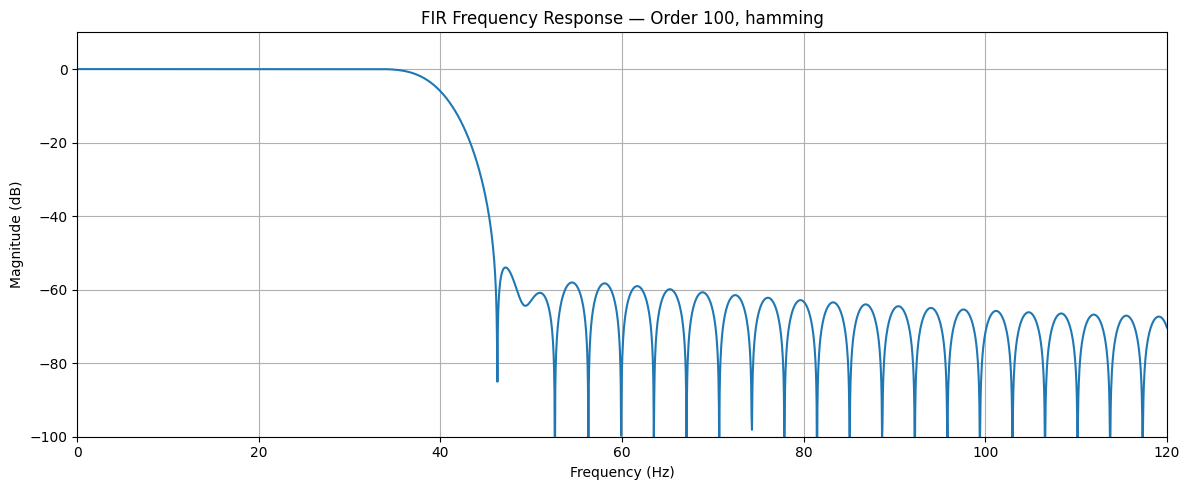


15a. TRAINING 1D CNN
Training windows  : 2160  (720 samples each)
Validation windows: 72


Model: "ecg_cnn_refiner"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, None, 32)  │        320 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, None, 32)  │      9,248 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, None, 64)  │     18,496 │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, None, 64)  │     36,928 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, None, 32)  │     18,464 │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, None, 32)  │      9,248 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, None, 1)   │        289 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, None, 1)   │          0 │ input_layer[0][0… │
│                     │                   │            │ conv1d_6[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 92,993 (363.25 KB)

 Trainable params: 92,993 (363.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
68/68 - 31s - 457ms/step - loss: 0.0017 - val_loss: 0.0014
Epoch 2/40
68/68 - 28s - 411ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 3/40
68/68 - 41s - 604ms/step - loss: 0.0013 - val_loss: 0.0012
Epoch 4/40
68/68 - 41s - 599ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 5/40
68/68 - 28s - 408ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 6/40
68/68 - 41s - 609ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 7/40
68/68 - 28s - 410ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 8/40
68/68 - 41s - 601ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 9/40
68/68 - 28s - 413ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 10/40
68/68 - 41s - 599ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 11/40
68/68 - 41s - 601ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 12/40
68/68 - 41s - 607ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 13/40
68/68 - 41s - 597ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 14/40
68/68 - 28s - 410ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 15/40
68/

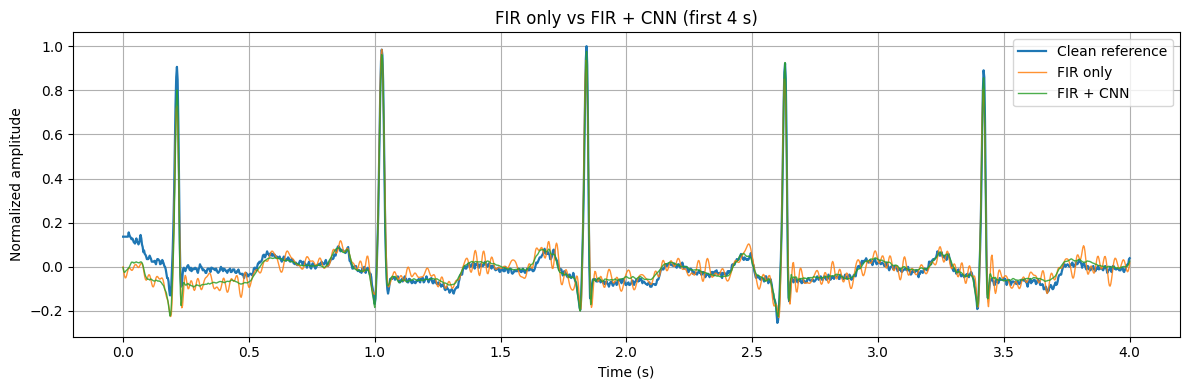

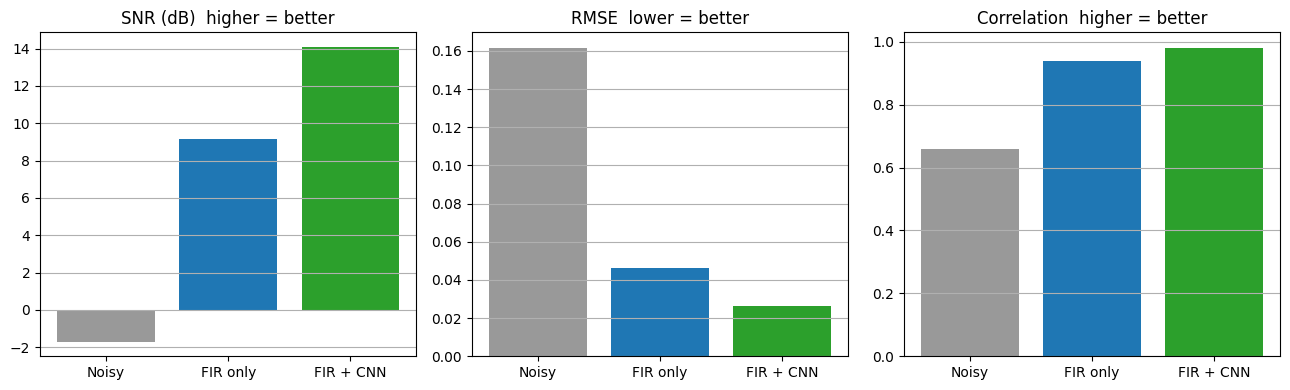

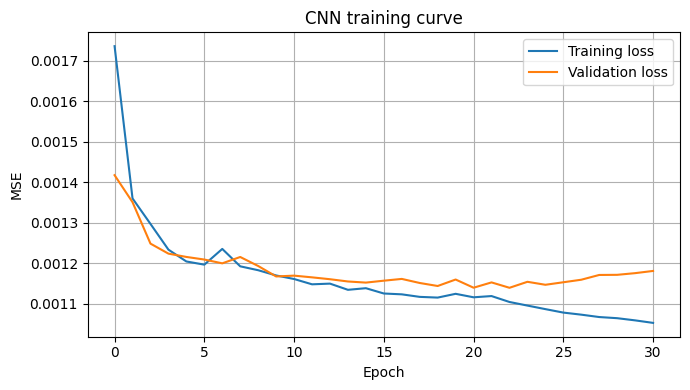


FILTER ORDER + WINDOW COMPARISON
  Window  Order  Input_SNR_dB  Output_SNR_dB  SNR_Improvement_dB      MSE     RMSE  Correlation
 hamming     20     -1.694394       8.809006           10.503400 0.002327 0.048237     0.932694
 hamming     40     -1.694394       9.189710           10.884104 0.002132 0.046169     0.939565
 hamming     60     -1.694394       9.177929           10.872324 0.002137 0.046232     0.939686
 hamming     80     -1.694394       9.159342           10.853736 0.002147 0.046331     0.939568
 hamming    100     -1.694394       9.140587           10.834981 0.002156 0.046431     0.939462
    hann     20     -1.694394       8.676397           10.370791 0.002399 0.048980     0.930732
    hann     40     -1.694394       9.180838           10.875232 0.002136 0.046216     0.939431
    hann     60     -1.694394       9.172672           10.867066 0.002140 0.046260     0.939775
    hann     80     -1.694394       9.154993           10.849388 0.002149 0.046354     0.939692
    ha

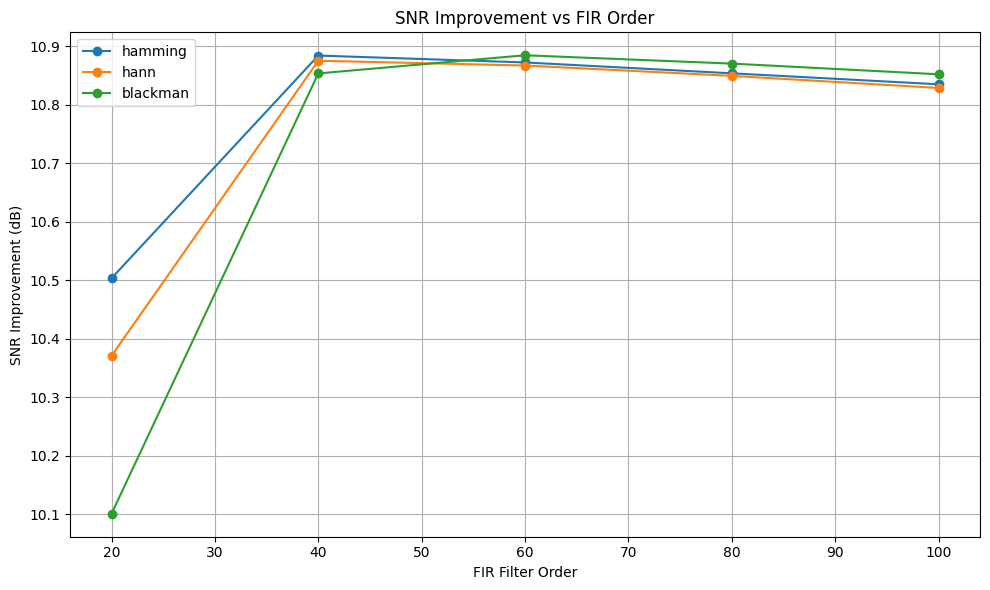

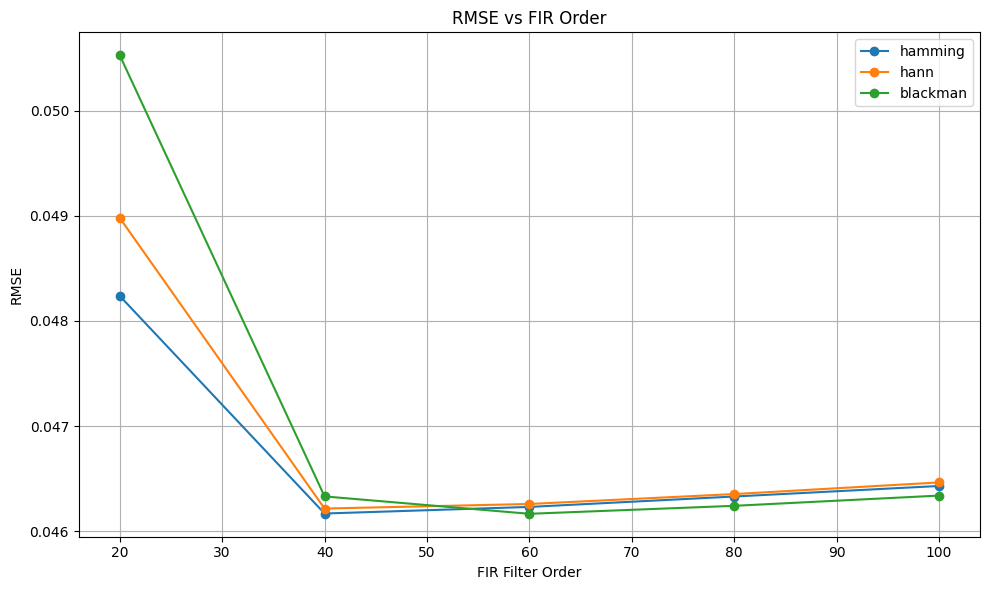

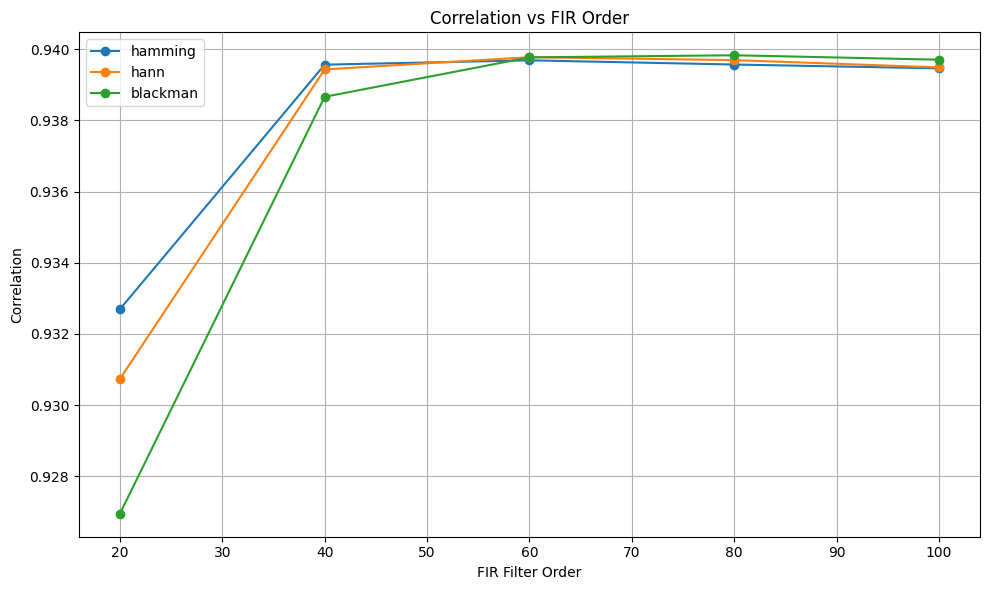


EXPERIMENTAL CONFIGURATION WITH MAXIMUM SNR IMPROVEMENT
Window : blackman
Order  : 60
SNR improvement : 10.885 dB

INDIVIDUAL NOISE EXPERIMENT
     Noise_Type  Input_SNR_dB  Output_SNR_dB  SNR_Improvement_dB     RMSE  Correlation
Baseline Wander      1.666827      13.212012           11.545185 0.029056     0.976047
50 Hz Powerline      7.425197      11.940101            4.514903 0.033638     0.967789
      EMG Noise      4.414898      12.599849            8.184952 0.031178     0.972178
   AWGN (10 dB)     10.000000      10.537630            0.537630 0.039532     0.956022


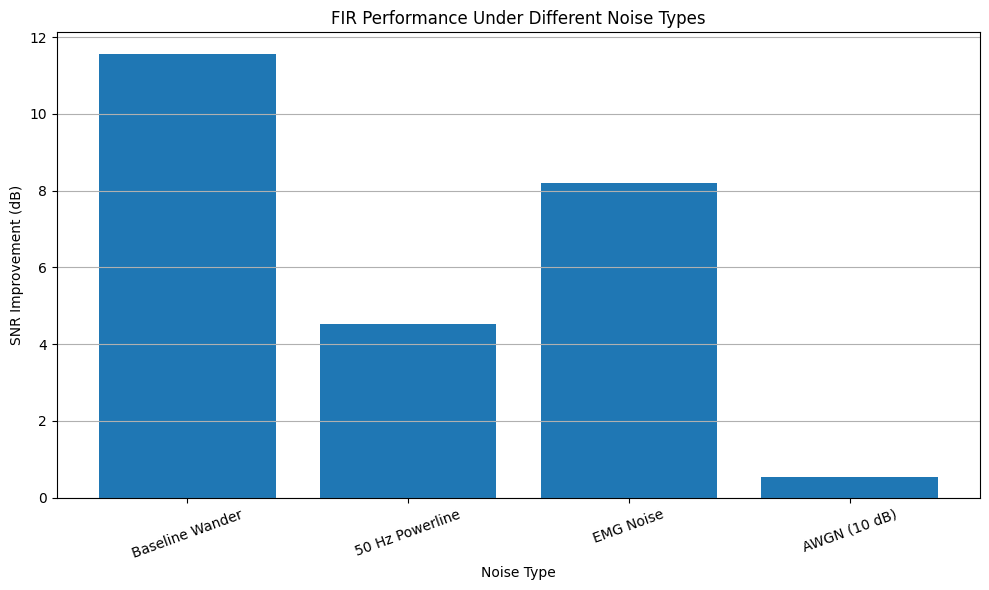


INPUT SNR SWEEP
 Target_Input_SNR_dB  Measured_Input_SNR_dB  Output_SNR_dB  SNR_Improvement_dB     RMSE  Correlation
                   0                    0.0       5.832008            5.832008 0.067957     0.881568
                   5                    5.0       9.766682            4.766682 0.043202     0.948155
                  10                   10.0      11.975884            1.975884 0.033500     0.968159
                  15                   15.0      12.136893           -2.863107 0.032884     0.969073
                  20                   20.0      12.284660           -7.715340 0.032330     0.970040


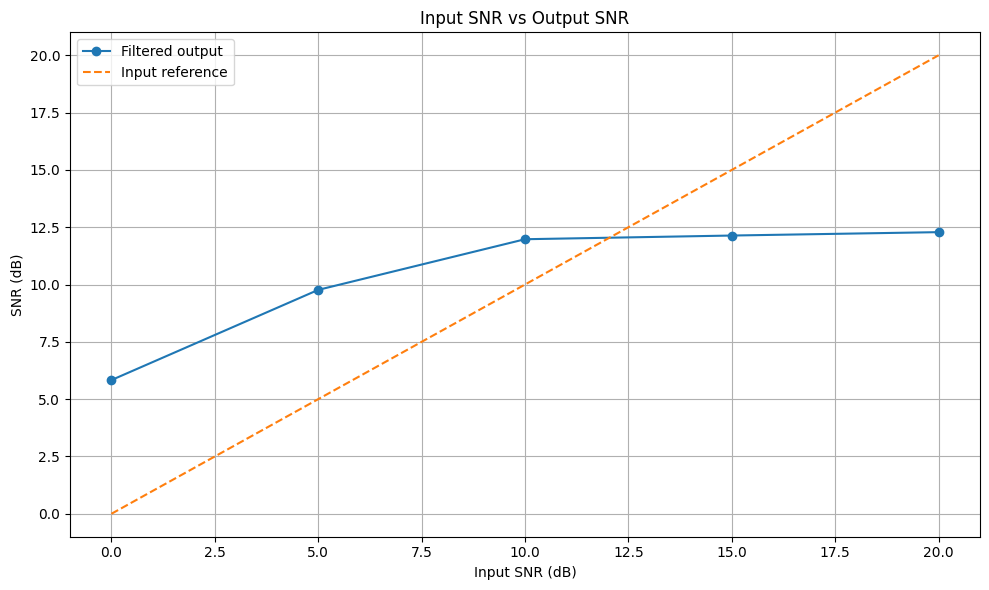


R-PEAK / QRS PRESERVATION
Reference R-peaks detected : 13
Noisy R-peaks detected     : 23
Filtered R-peaks detected  : 13

  Signal  TP  FP  FN  Precision   Recall       F1
   Noisy   8  15   5   0.347826 0.615385 0.444444
Filtered  13   0   0   1.000000 1.000000 1.000000


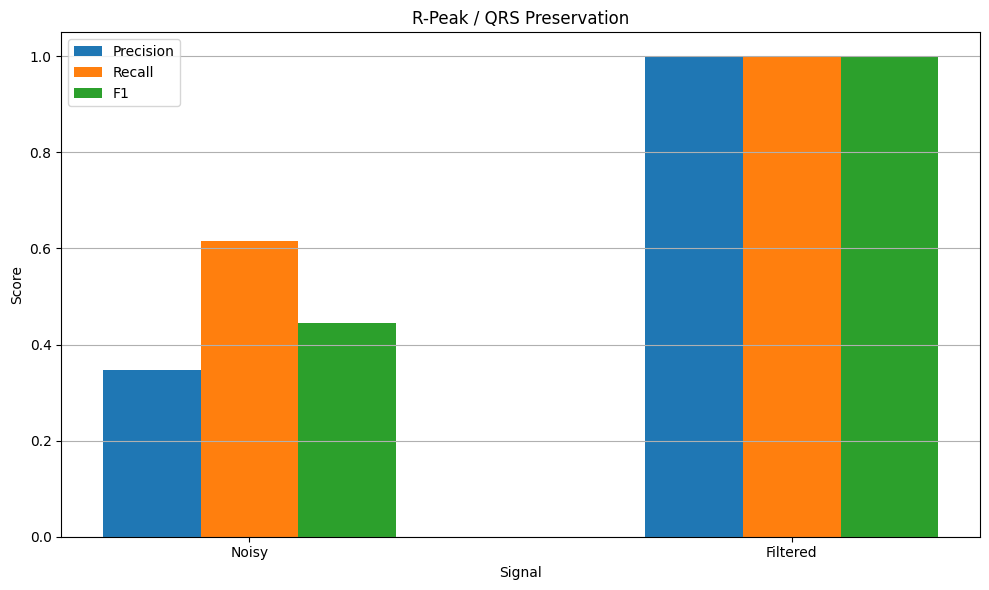


ECG SIGNAL DENOISING PROJECT — VERSION 2

Data:
    Database: MIT-BIH Arrhythmia Database
    Record: 100
    Duration: 10 seconds

Final mixed-noise experiment:
    Input SNR       : -1.6944 dB
    Output SNR      : 9.1406 dB
    SNR Improvement : 10.8350 dB
    RMSE            : 0.04643073
    Correlation     : 0.939462

Experimental filter configuration with maximum
SNR improvement in the comparison table:
    Window          : blackman
    Order           : 60
    SNR Improvement : 10.8846 dB
    RMSE            : 0.04616624
    Correlation     : 0.939769

QRS/R-peak preservation:
  Signal  TP  FP  FN  Precision   Recall       F1
   Noisy   8  15   5   0.347826 0.615385 0.444444
Filtered  13   0   0   1.000000 1.000000 1.000000

Interpretation:
The project evaluates software-based ECG signal-quality
improvement under controlled synthetic noise. Results are
quantitative signal-processing measurements and should not
be interpreted as clinical diagnosis or clinical validation.


PROJ

In [33]:
# ============================================================
# 14. MAIN
# ============================================================

def main():

    print_header(
        "ECG SIGNAL DENOISING AND QUALITY ENHANCEMENT — VERSION 2"
    )

    # --------------------------------------------------------
    # Load real ECG
    # --------------------------------------------------------

    t, clean, fs = load_real_ecg()

    # --------------------------------------------------------
    # Plot clean ECG
    # --------------------------------------------------------

    plot_clean_ecg(
        t,
        clean
    )

    # --------------------------------------------------------
    # Create mixed noisy ECG
    # --------------------------------------------------------

    print_header("2. MIXED NOISE GENERATION")

    noisy = create_mixed_noise(
        clean,
        fs,
        MIXED_INPUT_SNR_DB
    )

    plot_noisy_ecg(
        t,
        noisy
    )

    input_snr = snr(
        clean,
        noisy
    )

    print(
        f"Measured input SNR: "
        f"{input_snr:.3f} dB"
    )

    # --------------------------------------------------------
    # Main FIR filter
    # --------------------------------------------------------

    print_header("3. MAIN FIR FILTER")

    main_order = 100
    main_window = "hamming"

    coefficients = design_fir(
        fs,
        main_order,
        main_window
    )

    filtered = apply_fir(
        noisy,
        coefficients
    )

    output_snr = snr(
        clean,
        filtered
    )

    improvement = (
        output_snr - input_snr
    )

    final_rmse = rmse(
        clean,
        filtered
    )

    final_corr = correlation(
        clean,
        filtered
    )

    print(
        f"Filter order      : {main_order}"
    )

    print(
        f"Window            : {main_window}"
    )

    print(
        f"Input SNR         : {input_snr:.3f} dB"
    )

    print(
        f"Output SNR        : {output_snr:.3f} dB"
    )

    print(
        f"SNR improvement   : {improvement:.3f} dB"
    )

    print(
        f"RMSE              : {final_rmse:.6f}"
    )

    print(
        f"Correlation       : {final_corr:.6f}"
    )

    # --------------------------------------------------------
    # Main plots
    # --------------------------------------------------------

    plot_filtered_ecg(
        t,
        filtered
    )

    plot_three_signals(
        t,
        clean,
        noisy,
        filtered
    )

    plot_fft_separate(
        noisy,
        filtered,
        fs
    )

    plot_fir_response(
        coefficients,
        fs,
        main_order,
        main_window
    )

    fir_fn = lambda x: apply_fir(x, coefficients)
    cnn_df, cnn_out = cnn_experiment(t, clean, noisy, filtered, fs, fir_fn)

    # --------------------------------------------------------
    # Filter comparison
    # --------------------------------------------------------

    filter_df = filter_comparison(
        clean,
        noisy,
        fs
    )

    plot_filter_comparison(
        filter_df
    )

    best = select_best_configuration(
        filter_df
    )

    print_header("EXPERIMENTAL CONFIGURATION WITH MAXIMUM SNR IMPROVEMENT")

    print(
        f"Window : {best['Window']}"
    )

    print(
        f"Order  : {int(best['Order'])}"
    )

    print(
        f"SNR improvement : "
        f"{best['SNR_Improvement_dB']:.3f} dB"
    )

    # --------------------------------------------------------
    # Noise type comparison
    # --------------------------------------------------------

    noise_df = noise_type_experiment(
        clean,
        fs,
        coefficients
    )

    plot_noise_comparison(
        noise_df
    )

    # --------------------------------------------------------
    # SNR sweep
    # --------------------------------------------------------

    sweep_df = snr_sweep(
        clean,
        fs,
        coefficients
    )

    plot_snr_sweep(
        sweep_df
    )

    # --------------------------------------------------------
    # QRS/R-peak preservation
    # --------------------------------------------------------

    qrs_df, clean_peaks, noisy_peaks, filtered_peaks = (
        qrs_preservation_experiment(
            clean,
            noisy,
            filtered,
            fs
        )
    )

    plot_qrs_comparison(
        qrs_df
    )

    # --------------------------------------------------------
    # Save final summary
    # --------------------------------------------------------

    save_summary(
        best,
        input_snr,
        output_snr,
        improvement,
        final_rmse,
        final_corr,
        qrs_df
    )

    # --------------------------------------------------------
    # Final message
    # --------------------------------------------------------

    print_header("PROJECT COMPLETED")

    print("All plots saved in:")
    print(PLOT_DIR)

    print("\nAll CSV results saved in:")
    print(RESULT_DIR)

    print("\nImportant files:")
    print("  filter_comparison.csv")
    print("  noise_comparison.csv")
    print("  snr_sweep.csv")
    print("  qrs_comparison.csv")
    print("  best_configuration.txt")



main()


## Output

Generated files are saved under `/content/plots/` and `/content/results/`.

You can inspect CSV results with pandas or download the folders from the Colab file browser.
